# King County House Prices Project

Your task is to **predict the sale price of a house** in King County with a regression model, and to **tune** the model with cross-validation. In the project you combine the methods you already know into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked and the models are scored on the test set](assets/king_county_project_workflow.png)

# Data Description

King County covers Seattle and its surroundings. The data ships with this repository as **two tables**:

- `data/king_county_house_sales.csv`: one row per sale, with the date and the price
- `data/king_county_house_details.csv`: one row per house, with its physical attributes

`01_loading_the_data.ipynb` guides you through combining them into one table.

| Column | Table | Description |
| :-- | :-- | :-- |
| `date` | sales | date the house was sold |
| `price` | sales | sale price in dollars, the prediction target |
| `house_id` | sales | identifier of the house, matches `id` in the details table |
| `id` | sales | identifier of the sale |
| `id` | details | unique identifier for a house |
| `bedrooms` | details | number of bedrooms |
| `bathrooms` | details | number of bathrooms |
| `sqft_living` | details | square footage of the home |
| `sqft_lot` | details | square footage of the lot |
| `floors` | details | total floors (levels) in the house |
| `waterfront` | details | whether the house has a view to a waterfront |
| `view` | details | quality of the view |
| `condition` | details | overall condition of the house |
| `grade` | details | overall grade given to the housing unit, based on the King County grading system |
| `sqft_above` | details | square footage of the house apart from the basement |
| `sqft_basement` | details | square footage of the basement |
| `yr_built` | details | year the house was built |
| `yr_renovated` | details | year the house was renovated |
| `zipcode` | details | zip code |
| `lat` | details | latitude coordinate |
| `long` | details | longitude coordinate |
| `sqft_living15` | details | square footage of the interior living space of the nearest 15 neighbours |
| `sqft_lot15` | details | square footage of the land lots of the nearest 15 neighbours |

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why.
2. **Get the data.** Complete `01_loading_the_data.ipynb` first: it combines the two tables and saves the result as `data/eda.csv`, which you load here.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `price` column. You do not need a separate validation set: in step 7, cross-validation on the training set takes its place. Do not look at `df_test` until step 8.
4. **Explore the training set.** Which columns are related to the price, and which one most strongly? Which columns are skewed, which values are missing, and which features contain the same information?

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, a new column such as the age of the house at sale, or dropping the identifiers `id` and `house_id` and the `date` column. Transformations inside your `Pipeline` (imputing, scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean price of the training set for every house, and
    - a **rule-based baseline** built from the column most strongly related to the price in step 4. Learn the values of the rule on the training data.
6. **Build a preprocessing pipeline and train a linear model.** Put every transformation into a `Pipeline` with a `ColumnTransformer`, so that it is fitted on the training data only, and train a regularised linear model, for example `Ridge`, with as many features as possible.
7. **Tune and compare models with cross-validation.** Train and tune at least two models, for example `Ridge` on the original features and on polynomial features: first a wide `RandomizedSearchCV`, then a narrow `GridSearchCV` around what it found. Choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, and how large is the difference between training and test scores? Finally, **analyse the residuals** of your best model: for which houses is it wrong, and how large are the errors?

In [1]:
# Libraries used in this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

## 1. Goal and Metric

**Goal:** predict the sale price of a house in King County, a **regression** problem.

| | Metric | Why |
|:--|:--|:--|
| **Main** | **RMSE** (root mean squared error) | In dollars, so it is easy to explain (*"on average the model is off by \$X"*). Errors are squared, so large mistakes on expensive houses count more. Also used as the scoring for cross-validation. |
| **Second** | **R²** | The share of the price variation the model explains. Makes the comparison with the mean baseline (R² ≈ 0) easy. |

**Metrics we did not choose:**

- **MSE**: same ranking as RMSE, but in dollars², so it cannot be interpreted.
- **MAE** (mean absolute error): treats all errors equally, so it barely notices the big misses on expensive houses.
- **Adjusted R²**: cross-validation already penalises overfitting, by scoring on data the model has not seen.
- **Accuracy, precision, recall, F1**: classification metrics; we predict a number, not a class.

## 2. Get the Data

We load the combined table that `01_loading_the_data.ipynb` saved: **one row per sale**, 21,597 sales and 23 columns.

In [2]:
df = pd.read_csv("data/eda.csv")

print(f"Dataset shape: {df.shape}")
#df.head(3)
#df.info()
df.describe(include="all").T

Dataset shape: (21597, 23)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,21597,372,2014-06-23,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,21597.0,NaN,NaN,NaN,540296.573506,367368.140101,78000.0,322000.0,450000.0,645000.0,7700000.0
house_id,21597.0,NaN,NaN,NaN,4580474287.770987,2876735715.74778,1000102.0,2123049175.0,3904930410.0,7308900490.0,9900000190.0
id,21597.0,NaN,NaN,NaN,10799.0,6234.661218,1.0,5400.0,10799.0,16198.0,21597.0
id_details,21597.0,NaN,NaN,NaN,4580474287.770987,2876735715.74778,1000102.0,2123049175.0,3904930410.0,7308900490.0,9900000190.0
bedrooms,21597.0,NaN,NaN,NaN,3.371811,0.904096,1.0,3.0,3.0,4.0,11.0
bathrooms,21597.0,NaN,NaN,NaN,2.115826,0.768984,0.5,1.75,2.25,2.5,8.0
sqft_living,21597.0,NaN,NaN,NaN,2080.32185,918.106125,370.0,1430.0,1910.0,2550.0,13540.0
sqft_lot,21597.0,NaN,NaN,NaN,15099.40876,41412.636876,520.0,5040.0,7618.0,10685.0,1651359.0
floors,21597.0,NaN,NaN,NaN,1.494096,0.539683,1.0,1.0,1.5,2.0,3.5


## 3. Train-Test Split

We split **once, before exploring**, so the test set stays truly unseen.

- **20% test set (4,320 sales):** large enough for a reliable score, while 17,277 sales remain for training.
- **`random_state=42`:** the same split on every run.
- **No separate validation set:** cross-validation on the training set takes its place in step 7.

In [3]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"train: {df_train.shape}")
print(f"test:  {df_test.shape}")


train: (17277, 23)
test:  (4320, 23)


## 4. Explore the Training Set

All exploration uses **`df_train` only**. We look at four questions from the task:

1. **Missing values:** which columns have gaps, and how do we fill them? (4.1–4.4)
2. **Skew:** how is the price distributed? (4.5)
3. **Relationships:** which features are related to the price, and which ones contain the same information? (4.6–4.8)
4. **Location:** how much does *where* a house is matter? (4.9)

Every change we make by hand is collected in **4.10**.

In [4]:
# data types and missing values on the training set
print(df_train.dtypes)
print(df_train.isna().sum())


date                 str
price            float64
house_id           int64
id                 int64
id_details         int64
bedrooms         float64
bathrooms        float64
sqft_living      float64
sqft_lot         float64
floors           float64
waterfront       float64
view             float64
condition          int64
grade              int64
sqft_above       float64
sqft_basement    float64
yr_built           int64
yr_renovated     float64
zipcode            int64
lat              float64
long             float64
sqft_living15    float64
sqft_lot15       float64
dtype: object
date                0
price               0
house_id            0
id                  0
id_details          0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       1907
view               53
condition           0
grade               0
sqft_above          0
sqft_basement     356
yr_built            0
yr_renovated     3069
zipcode        

In [5]:
# only the columns that actually have missing values
missing = df_train.isna().sum()
missing[missing > 0]


waterfront       1907
view               53
sqft_basement     356
yr_renovated     3069
dtype: int64

Four columns have missing values: `waterfront`, `view`, `sqft_basement` and `yr_renovated`. For each one we check **what the values mean** and **whether they matter for the price**, and then decide how to handle the gaps.

### 4.1 Waterfront

In [6]:
print(df_train["waterfront"].value_counts(dropna=False))
df_train.groupby("waterfront", dropna=False)["price"].median()


waterfront
0.0    15252
NaN     1907
1.0      118
Name: count, dtype: int64


waterfront
0.0     450000.0
1.0    1600000.0
NaN     440000.0
Name: price, dtype: float64

> **Finding:** Only 118 houses (0.7%) are on the waterfront, but their median price (**\$1.6M**) is about **3.5× higher** than for other houses (\$450k). The 1,907 houses with a missing value have a similar median price (\$440k) as the non-waterfront houses.
>
> **Decision:** we impute the missing values with **0** (the most frequent value) in the pipeline.

### 4.2 View

In [7]:
print(df_train["view"].value_counts(dropna=False).sort_index())
df_train.groupby("view", dropna=False)["price"].median()


view
0.0    15556
1.0      257
2.0      753
3.0      395
4.0      263
NaN       53
Name: count, dtype: int64


view
0.0     433750.0
1.0     699000.0
2.0     680000.0
3.0     800000.0
4.0    1200000.0
NaN     480000.0
Name: price, dtype: float64

> **Finding:** 90% of the houses have no special view (0). The median price rises with the view rating, from **\$434k** (0) to **\$1.2M** (4), so `view` is a useful feature. Only 53 values (0.3%) are missing.
>
> **Decision:** with so few gaps, we simply impute the **most frequent value (0)** in the pipeline.

### 4.3 Basement Area

In [8]:
# check the redundancy
has_value = df_train["sqft_basement"].notna()
same = (df_train["sqft_above"] + df_train["sqft_basement"] == df_train["sqft_living"])[has_value]
print("above + basement == living:", same.mean())

print("no basement (0):", (df_train["sqft_basement"] == 0).sum())
print("with basement:  ", (df_train["sqft_basement"] > 0).sum())

# does having a basement matter for price? (computed from living - above, so no missing values)
has_basement = (df_train["sqft_living"] - df_train["sqft_above"]) > 0
df_train.groupby(has_basement)["price"].median()


above + basement == living: 1.0
no basement (0): 10249
with basement:   6672


False    412500.0
True     515000.0
Name: price, dtype: float64

> **Finding:** `sqft_basement` always equals `sqft_living − sqft_above` (true for 100% of the rows), so it adds no new information. Houses with a basement have a higher median price (\$515k vs. \$412.5k).
>
> **Decision:** we **drop** `sqft_basement`, so its 356 missing values need no imputing, and keep the information as a yes/no column **`has_basement`**, computed from `sqft_living − sqft_above`.

### 4.4 Renovation Year

In [9]:
print("never renovated (0):", (df_train["yr_renovated"] == 0).sum())
print("renovated (> 0):    ", (df_train["yr_renovated"] > 0).sum())
print("missing (NaN):      ", df_train["yr_renovated"].isna().sum())

print(df_train.groupby(df_train["yr_renovated"] > 0)["price"].median())
print(df_train.groupby(df_train["yr_renovated"].isna())["price"].median())


never renovated (0): 13615
renovated (> 0):     593
missing (NaN):       3069
yr_renovated
False    449000.0
True     625000.0
Name: price, dtype: float64
yr_renovated
False    450000.0
True     450000.0
Name: price, dtype: float64


> **Finding:** Only 593 houses (3.4%) were ever renovated; the value 0 means *never renovated*, so the column is not a real year. Renovated houses have a higher median price (**\$625k vs. \$449k**). The 3,069 missing values have the same median price as the rest (\$450k).
>
> **Decision:** we treat missing values as *not renovated* and replace `yr_renovated` with a yes/no column **`renovated`**.

### 4.5 Price Distribution

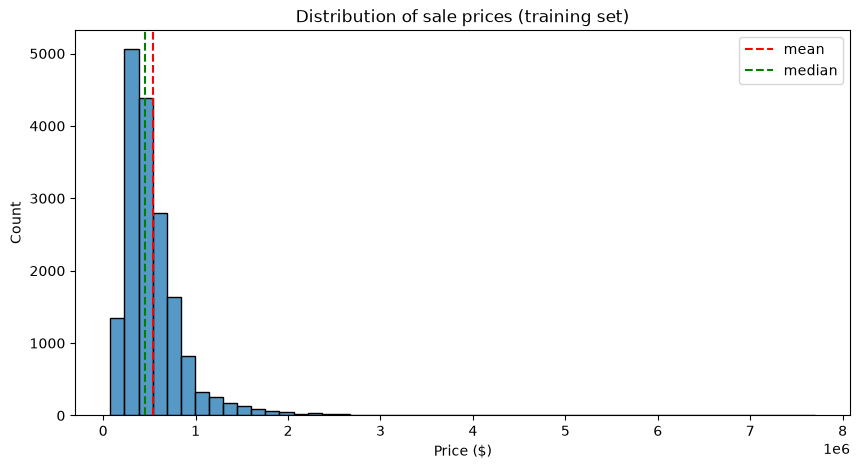

skew: 3.95
share above $1M: 0.068


In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_train["price"], bins=50, ax=ax)

# mean and median as vertical lines
ax.axvline(df_train["price"].mean(), color="red", linestyle="--", label="mean")
ax.axvline(df_train["price"].median(), color="green", linestyle="--", label="median")

ax.set_title("Distribution of sale prices (training set)")
ax.set_xlabel("Price ($)")
ax.legend()
plt.show()

print("skew:", df_train["price"].skew().round(2))
print("share above $1M:", (df_train["price"] > 1_000_000).mean().round(3))


> **Finding:** The price is strongly **right-skewed (skew 3.95)**: the median is \$450k, but a long tail reaches several million, and 6.8% of the houses cost more than \$1M.
>
> **Consequence:** we expect the largest errors on these expensive houses. A log transformation of the price would reduce the skew (to about 0.43), an idea for step 7.

### 4.6 Correlation with Price

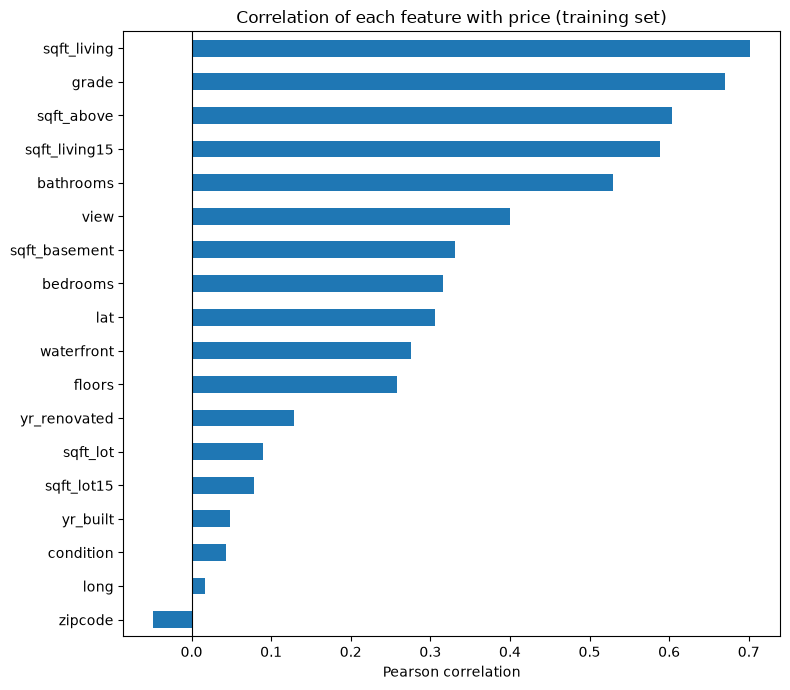

sqft_living      0.70
grade            0.67
sqft_above       0.60
sqft_living15    0.59
bathrooms        0.53
view             0.40
sqft_basement    0.33
bedrooms         0.32
lat              0.31
waterfront       0.28
floors           0.26
yr_renovated     0.13
sqft_lot         0.09
sqft_lot15       0.08
yr_built         0.05
condition        0.04
long             0.02
zipcode         -0.05
Name: price, dtype: float64

In [11]:
# 1. numeric columns only, without the identifiers
numeric = df_train.select_dtypes("number").drop(columns=["id", "house_id", "id_details"])

# 2. correlation of every column with price, without price itself
corr_price = numeric.corr()["price"].drop("price").sort_values()

# 3. horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 7))
corr_price.plot(kind="barh", ax=ax)
ax.axvline(0, color="black", linewidth=0.8)   # zero line
ax.set_title("Correlation of each feature with price (training set)")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

corr_price.sort_values(ascending=False).round(2)


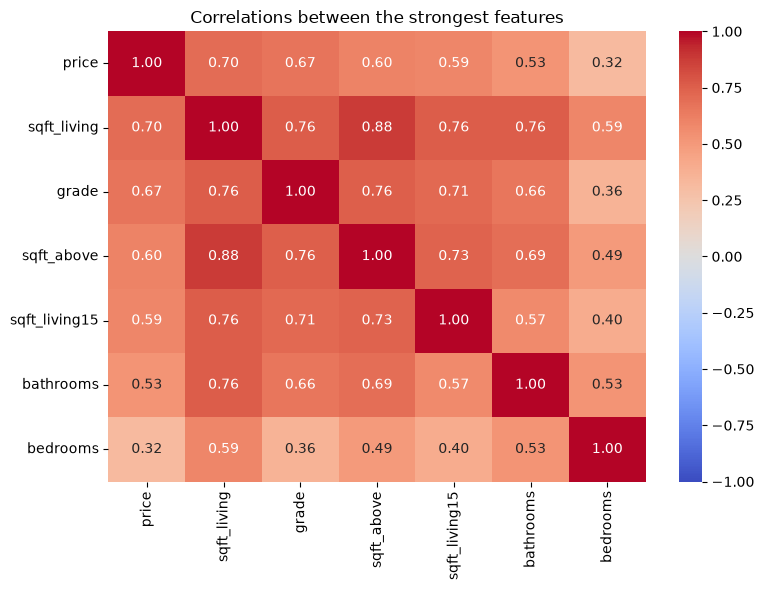

In [12]:
top = ["price", "sqft_living", "grade", "sqft_above", "sqft_living15", "bathrooms", "bedrooms"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df_train[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlations between the strongest features")
plt.tight_layout()
plt.show()



> **Finding:** `sqft_living` is most strongly related to the price (**r = 0.70**), followed by `grade` (0.67). `sqft_living`, `sqft_above` and `sqft_living15` are strongly correlated with each other (0.76–0.88): they all mostly measure the **size** of the house. `zipcode` shows almost no linear correlation, because its numbers are labels, not quantities.
>
> **Decision:** we drop the exact duplicate `sqft_basement` and keep the other size features: Ridge regularisation keeps the coefficients stable when features are correlated, but we do not interpret their coefficients individually. `zipcode` is encoded as a category.

### 4.7 Living Area vs. Price

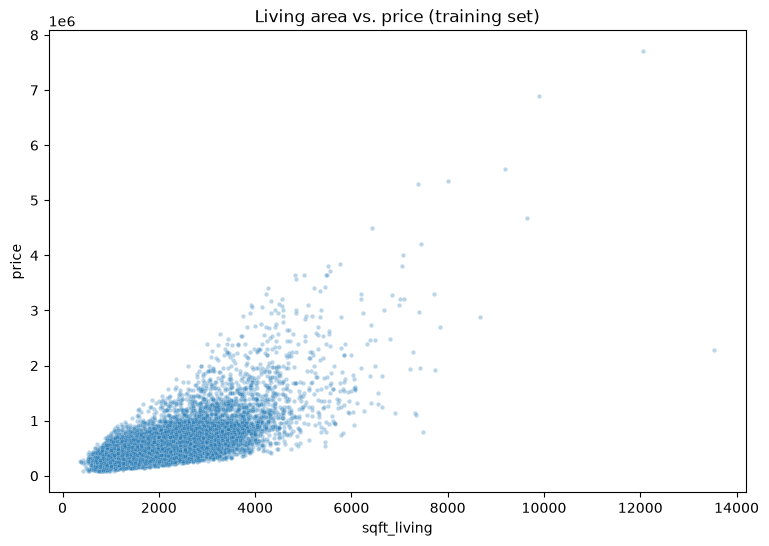

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df_train, x="sqft_living", y="price", alpha=0.3, s=10, ax=ax)
ax.set_title("Living area vs. price (training set)")
plt.show()


> **Finding:** a clear upward trend, but the spread grows for bigger houses (a funnel shape), so **large houses are harder to predict**.

### 4.8 Price by Grade

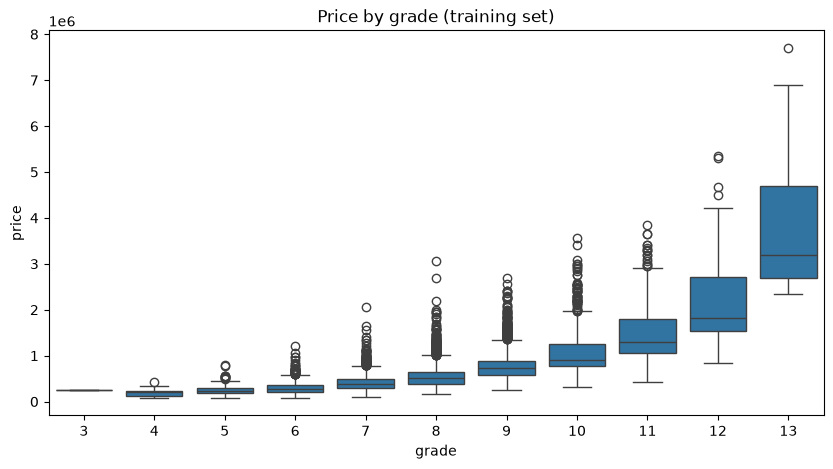

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_train, x="grade", y="price", ax=ax)
ax.set_title("Price by grade (training set)")
plt.show()


> **Finding:** the price rises **faster and faster** with the grade: the relationship is a curve, not a straight line. This is an argument for **polynomial features** in step 7.

### 4.9 Location

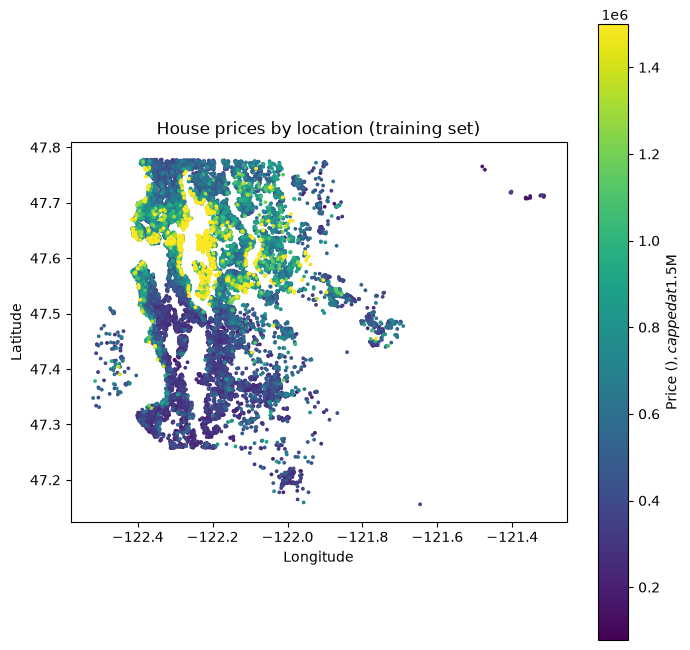

In [15]:
# sort by price so the expensive houses are drawn last (on top)
plot_data = df_train.sort_values("price")

fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(plot_data["long"], plot_data["lat"], c=plot_data["price"],
                cmap="viridis", s=3, vmax=1_500_000)
plt.colorbar(sc, label="Price ($), capped at $1.5M")

# correct proportions: 1° longitude is shorter than 1° latitude at 47.5° N
ax.set_aspect(1 / np.cos(np.radians(47.5)))

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("House prices by location (training set)")
plt.show()


> **Finding:** prices depend strongly on location. The most expensive houses are around **Seattle, Bellevue and the shores of Lake Washington**, while the south of the county is clearly cheaper.
>
> **Decision:** this pattern is not linear in `lat` or `long`, so we **one-hot encode `zipcode`**, and the model can learn a price level for each area.

### 4.10 Manual Changes

Every change we make to the data by hand goes into one function, `prepare()`, so the changes are documented in one place and can be repeated **exactly the same way**. Imputing, scaling and encoding happen inside the pipeline in step 6.

| # | Change | Reason |
|:--|:--|:--|
| 1 | New column `renovated`: 1 if `yr_renovated` > 0, else 0 (missing → 0) | 0 means *never renovated*, not a real year (4.4) |
| 2 | New column `has_basement`: 1 if `sqft_living − sqft_above` > 0, else 0 | Keeps the basement information without the redundant column (4.3) |
| 3 | New column `age`: sale year − `yr_built` | The age at sale is more meaningful than the build year |
| 4 | Drop `id`, `house_id`, `id_details` | Identifiers, no information about the price |
| 5 | Drop `date`, `sqft_basement`, `yr_renovated` | Replaced by `age`, `has_basement` and `renovated` |

In [16]:
def prepare(data):
    """All manual changes to the data, collected in one place."""
    data = data.copy()

    # 1. renovated: 1 if the house was ever renovated, else 0 (NaN > 0 is False, so NaN counts as 0)
    data["renovated"] = (data["yr_renovated"] > 0).astype(int)

    # 2. has_basement: 1 if there is living area outside sqft_above
    data["has_basement"] = ((data["sqft_living"] - data["sqft_above"]) > 0).astype(int)

    # 3. age of the house at the time of sale
    sale_year = pd.to_datetime(data["date"]).dt.year
    data["age"] = sale_year - data["yr_built"]

    # 4. drop identifiers, the raw date and the replaced/redundant columns
    data = data.drop(columns=["id", "house_id", "id_details", "date", "sqft_basement", "yr_renovated"])

    return data


df_train_prep = prepare(df_train)
print(df_train_prep.shape)
df_train_prep.head()


(17277, 20)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,yr_built,zipcode,lat,long,sqft_living15,sqft_lot15,renovated,has_basement,age
6243,332500.0,4.0,2.00,1440.0,4855.0,2.0,0.0,0.0,4,7,1440.0,1972,98144,47.5717,-122.287,1300.0,4080.0,0,0,42
8986,390000.0,3.0,1.75,1430.0,9857.0,1.0,0.0,2.0,4,7,1140.0,1980,98045,47.4964,-121.771,1310.0,9880.0,0,1,35
9419,800000.0,4.0,2.75,3120.0,5000.0,2.0,0.0,0.0,3,9,3120.0,2010,98074,47.5940,-122.062,3200.0,5000.0,0,0,4
10155,462000.0,4.0,2.50,2060.0,6958.0,1.0,0.0,0.0,3,7,1220.0,1974,98034,47.7251,-122.168,1760.0,7350.0,0,1,41
10436,695000.0,3.0,2.00,2500.0,4080.0,1.5,0.0,0.0,5,7,1680.0,1922,98103,47.6813,-122.346,1550.0,3060.0,0,1,92


## 5. Features, Target and Baselines

Before training real models, we build two simple baselines. Every model in steps 6 and 7 has to beat them; otherwise it is not worth its complexity.

### 5.1 Separate Features and Target

In [17]:
df_train_prep = prepare(df_train)

X_train = df_train_prep.drop(columns="price")
y_train = df_train_prep["price"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (17277, 19)
y_train: (17277,)


### 5.2 Mean Baseline

The simplest possible model predicts the **same price for every house**: the mean price of the training set.

In [18]:
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
pred_dummy_train = dummy.predict(X_train)

print(f"predicted price for every house: ${dummy.constant_[0][0]:,.0f}")
print(f"train RMSE: ${root_mean_squared_error(y_train, pred_dummy_train):,.0f}")
print(f"train R²:   {r2_score(y_train, pred_dummy_train):.3f}")

predicted price for every house: $541,519
train RMSE: $368,958
train R²:   0.000


### 5.3 Rule-Based Baseline

The rule uses the feature most strongly related to the price in step 4, `sqft_living` (r = 0.70):

> **price = typical price per square foot × living area**

We calculate the typical price per square foot as the **median**, so the luxury outliers do not pull it up.

In [19]:
# learn the rule on the training data
price_per_sqft = (y_train / X_train["sqft_living"]).median()

def rule_predict(X):
    return price_per_sqft * X["sqft_living"]

pred_rule_train = rule_predict(X_train)

print(f"median price per sqft: ${price_per_sqft:,.2f}")
print(f"train RMSE: ${root_mean_squared_error(y_train, pred_rule_train):,.0f}")
print(f"train R²:   {r2_score(y_train, pred_rule_train):.3f}")

median price per sqft: $244.44
train RMSE: $267,068
train R²:   0.476


### 5.4 Baseline Results

| Baseline | Train RMSE | Train R² |
|:--|--:|--:|
| Mean (always \$541,519) | \$368,958 | 0.000 |
| Rule (\$244.44 per sqft × living area) | \$267,068 | 0.476 |

> **Finding:** predicting the mean price is off by about **\$369k**. Using the living area alone lowers the error to about **\$267k** and explains **48%** of the price variation.
>
> **Consequence:** size alone gets us halfway. Our models in steps 6 and 7 have to clearly beat an RMSE of \$267k, by adding location, quality (`grade`, `view`) and the other features.

## 6. Preprocessing Pipeline and Linear Model

All transformations go into one `Pipeline` with a `ColumnTransformer`, so they are **fitted on the training data only** and can be repeated exactly on new data. The columns get different treatment:

| Column group | Columns | Steps |
|:--|:--|:--|
| **Numeric** | all except `zipcode` (18 columns) | impute missing values with the most frequent value (only `waterfront` and `view` have gaps) → standardise |
| **Categorical** | `zipcode` | one-hot encode, ignoring zip codes the model has not seen |

The model is a regularised linear model, `Ridge`, trained on all features. We score it with **5-fold cross-validation** on the training set.

In [20]:
categorical_features = ["zipcode"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", Ridge(alpha=1.0)),
])

# the same 5 folds for every model, so the scores are comparable
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rmse = -cross_val_score(ridge_pipe, X_train, y_train, cv=kfold, scoring="neg_root_mean_squared_error")

print("numeric features:", len(numeric_features))
print("columns after preprocessing:", ridge_pipe.fit(X_train, y_train)[:-1].transform(X_train).shape[1])
print(f"cross-validated RMSE: ${cv_rmse.mean():,.0f} (± ${cv_rmse.std():,.0f})")

numeric features: 18
columns after preprocessing: 88
cross-validated RMSE: $161,384 (± $14,131)


> **Finding:** with all features, location (70 zip codes) and the default `alpha=1`, Ridge reaches a cross-validated RMSE of about **\$161k**, much better than the rule-based baseline (\$267k). After one-hot encoding the model works with 88 columns.

## 7. Tuning and Comparing Models with Cross-Validation

We tune three models, each in two rounds: first a **wide `RandomizedSearchCV`** over the regularisation strength `alpha` (from 0.0001 to 10,000, on a log scale), then a **narrow `GridSearchCV`** around the best value it found. Every search uses the same 5 folds and RMSE as the scoring.

| # | Model | Idea from the exploration |
|:--|:--|:--|
| 7.1 | Ridge on the original features | baseline linear model from step 6 |
| 7.2 | Ridge on **polynomial features** (degree 2) | the price rises in a curve with `grade` (4.8) |
| 7.3 | Polynomial Ridge on **log(price)** | the price is strongly skewed (4.5) |

### 7.1 Ridge on the Original Features

In [21]:
ridge_random = RandomizedSearchCV(
    ridge_pipe,
    param_distributions={"model__alpha": loguniform(1e-4, 1e4)},
    n_iter=30,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
ridge_random.fit(X_train, y_train)
alpha_ridge = ridge_random.best_params_["model__alpha"]
print(f"randomized search: alpha = {alpha_ridge:.4f}, CV RMSE = ${-ridge_random.best_score_:,.0f}")

# narrow grid around the best alpha
ridge_grid = GridSearchCV(
    ridge_pipe,
    param_grid={"model__alpha": np.linspace(alpha_ridge / 3, alpha_ridge * 3, 15)},
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
ridge_grid.fit(X_train, y_train)
best_ridge = ridge_grid.best_estimator_
print(f"grid search:       alpha = {ridge_grid.best_params_['model__alpha']:.4f}, CV RMSE = ${-ridge_grid.best_score_:,.0f}")

randomized search: alpha = 0.0992, CV RMSE = $161,308


grid search:       alpha = 0.0708, CV RMSE = $161,308


> **Finding:** tuning barely changes the result (CV RMSE about **\$161k**). With 17k rows and 88 columns the linear model is not overfitting, so regularisation has little to correct. The limit is the model itself: a straight-line relationship cannot follow the curves we saw in the exploration.

### 7.2 Ridge on Polynomial Features

Only the **numeric** features are expanded into squares and pairwise products. `zipcode` stays one-hot encoded, so we do not create meaningless zip-code interactions.

In [22]:
poly_numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
])

poly_preprocessor = ColumnTransformer([
    ("num", poly_numeric_pipe, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

poly_pipe = Pipeline([
    ("prep", poly_preprocessor),
    ("model", Ridge()),
])

poly_random = RandomizedSearchCV(
    poly_pipe,
    param_distributions={"model__alpha": loguniform(1e-4, 1e4)},
    n_iter=30,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
poly_random.fit(X_train, y_train)
alpha_poly = poly_random.best_params_["model__alpha"]
print(f"randomized search: alpha = {alpha_poly:.5f}, CV RMSE = ${-poly_random.best_score_:,.0f}")

poly_grid = GridSearchCV(
    poly_pipe,
    param_grid={"model__alpha": np.linspace(alpha_poly / 3, alpha_poly * 3, 15)},
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
poly_grid.fit(X_train, y_train)
best_poly = poly_grid.best_estimator_
print(f"grid search:       alpha = {poly_grid.best_params_['model__alpha']:.5f}, CV RMSE = ${-poly_grid.best_score_:,.0f}")
print("columns after preprocessing:", best_poly[:-1].transform(X_train).shape[1])

randomized search: alpha = 0.00029, CV RMSE = $132,961


grid search:       alpha = 0.00049, CV RMSE = $132,944
columns after preprocessing: 259


> **Finding:** the polynomial features lower the CV RMSE from \$161k to about **\$133k**, a reduction of 18%. The model now works with 259 columns: 189 numeric terms plus 70 zip codes. The best `alpha` is very small, so with 17k training rows the model needs almost no regularisation.

### 7.3 Polynomial Ridge on log(price)

`TransformedTargetRegressor` trains the model on `log(price)` and converts its predictions back to dollars with `exp`, so the scores stay in dollars and are comparable with the other models.

In [23]:
log_poly_pipe = TransformedTargetRegressor(regressor=poly_pipe, func=np.log, inverse_func=np.exp)

log_random = RandomizedSearchCV(
    log_poly_pipe,
    param_distributions={"regressor__model__alpha": loguniform(1e-4, 1e4)},
    n_iter=30,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
log_random.fit(X_train, y_train)
alpha_log = log_random.best_params_["regressor__model__alpha"]
print(f"randomized search: alpha = {alpha_log:.3f}, CV RMSE = ${-log_random.best_score_:,.0f}")

log_grid = GridSearchCV(
    log_poly_pipe,
    param_grid={"regressor__model__alpha": np.linspace(alpha_log / 3, alpha_log * 3, 15)},
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
log_grid.fit(X_train, y_train)
best_log = log_grid.best_estimator_
print(f"grid search:       alpha = {log_grid.best_params_['regressor__model__alpha']:.3f}, CV RMSE = ${-log_grid.best_score_:,.0f}")

randomized search: alpha = 46.193, CV RMSE = $146,058


grid search:       alpha = 24.197, CV RMSE = $145,452


> **Finding:** on log(price) the CV RMSE is about **\$145k**: better than plain Ridge, but worse than the polynomial model on the original price. The log model is accurate in percent, but when it is wrong on an expensive house, converting back with `exp` turns that into a large dollar error, and RMSE punishes exactly these errors.

### 7.4 Choosing the Best Model

In [24]:
cv_results = pd.DataFrame({
    "Model": ["Ridge", "Polynomial Ridge", "Polynomial Ridge, log(price)"],
    "Best alpha": [
        ridge_grid.best_params_["model__alpha"],
        poly_grid.best_params_["model__alpha"],
        log_grid.best_params_["regressor__model__alpha"],
    ],
    "CV RMSE": [-ridge_grid.best_score_, -poly_grid.best_score_, -log_grid.best_score_],
}).set_index("Model")

cv_results["Best alpha"] = cv_results["Best alpha"].map("{:.5f}".format)
cv_results["CV RMSE"] = cv_results["CV RMSE"].map("${:,.0f}".format)
cv_results

,Best alpha,CV RMSE
Model,,
Ridge,0.07083,"$161,308"
Polynomial Ridge,0.00049,"$132,944"
"Polynomial Ridge, log(price)",24.19658,"$145,452"


> **Decision:** by its cross-validated score, the **Polynomial Ridge on the original price** is our best model (CV RMSE about \$133k). We choose the model by the CV score only, before looking at the test set.

## 8. Evaluation on the Test Set

### 8.1 Prepare the Test Set

We now unlock the test set. It gets exactly the same manual changes as the training data, with the same `prepare()` function. All other transformations are inside the pipelines and use the values learned on the training data.

In [25]:
df_test_prep = prepare(df_test)

X_test = df_test_prep.drop(columns="price")
y_test = df_test_prep["price"]

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (4320, 19)
y_test: (4320,)


### 8.2 Training and Test Scores of All Models

In [26]:
models = {
    "Mean baseline": dummy.predict,
    "Rule baseline (price per sqft)": rule_predict,
    "Ridge": best_ridge.predict,
    "Polynomial Ridge": best_poly.predict,
    "Polynomial Ridge, log(price)": best_log.predict,
}

rows = []
for name, predict in models.items():
    pred_train = predict(X_train)
    pred_test = predict(X_test)
    rows.append({
        "Model": name,
        "Train RMSE": root_mean_squared_error(y_train, pred_train),
        "Test RMSE": root_mean_squared_error(y_test, pred_test),
        "Train R²": r2_score(y_train, pred_train),
        "Test R²": r2_score(y_test, pred_test),
        "Test MAE": mean_absolute_error(y_test, pred_test),
    })

results = pd.DataFrame(rows).set_index("Model")

# formatted copy for display: dollars without decimals, R² with 3 decimals
results_display = results.copy()
for col in ["Train RMSE", "Test RMSE", "Test MAE"]:
    results_display[col] = results_display[col].map("${:,.0f}".format)
for col in ["Train R²", "Test R²"]:
    results_display[col] = results_display[col].map("{:.3f}".format)
results_display

,Train RMSE,Test RMSE,Train R²,Test R²,Test MAE
Model,,,,,
Mean baseline,"$368,958","$360,907",0.000,-0.000,"$231,542"
Rule baseline (price per sqft),"$267,068","$260,103",0.476,0.480,"$165,076"
Ridge,"$159,966","$161,928",0.812,0.799,"$96,657"
Polynomial Ridge,"$124,788","$123,699",0.886,0.882,"$75,896"
"Polynomial Ridge, log(price)","$127,071","$121,742",0.881,0.886,"$71,056"


| Model | Train RMSE | Test RMSE | Train R² | Test R² | Test MAE |
|:--|--:|--:|--:|--:|--:|
| Mean baseline | \$368,958 | \$360,907 | 0.000 | 0.000 | \$231,542 |
| Rule baseline (price per sqft) | \$267,068 | \$260,103 | 0.476 | 0.480 | \$165,076 |
| Ridge | \$159,966 | \$161,928 | 0.812 | 0.799 | \$96,657 |
| **Polynomial Ridge** | **\$124,788** | **\$123,699** | **0.886** | **0.882** | **\$75,896** |
| Polynomial Ridge, log(price) | \$127,071 | \$121,742 | 0.881 | 0.886 | \$71,056 |

> **Finding:**
> - **All three models beat both baselines clearly.** Our best model, the Polynomial Ridge, has a test RMSE of **\$124k**: 52% lower than the rule baseline (\$260k) and 66% lower than the mean baseline (\$361k). It explains **88%** of the price variation in the test set.
> - **Training and test scores are almost the same** for every model (Polynomial Ridge: \$125k vs. \$124k), so **no model overfits**. Cross-validation estimated the error well.
> - The log model is slightly better on the test set (\$122k), although its CV score was worse. The difference is small, and we keep the model we chose by CV: choosing by the test score would make the test set part of the model selection.

### 8.3 Residual Analysis of the Best Model

A residual is `actual price − predicted price`: positive means the model **underestimated** the house, negative means it **overestimated** it.

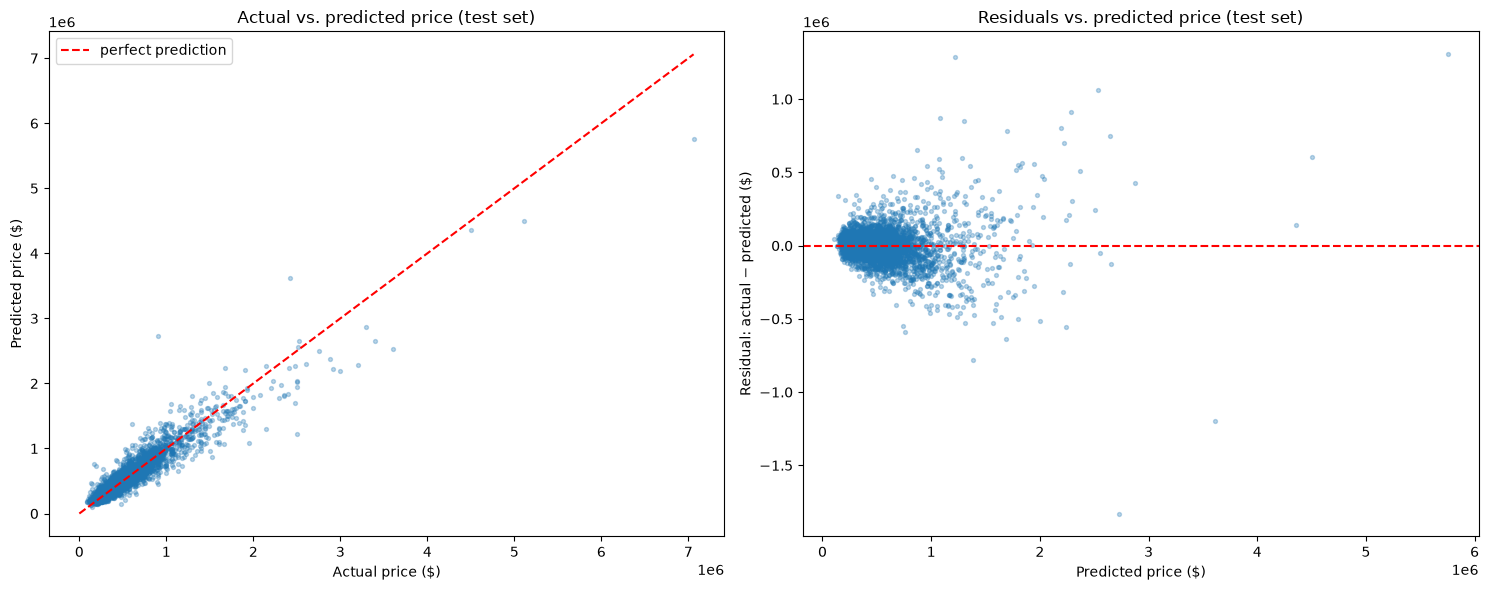

In [27]:
pred_best = best_poly.predict(X_test)
residuals = y_test - pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# actual vs. predicted
axes[0].scatter(y_test, pred_best, alpha=0.3, s=8)
limit = [0, y_test.max()]
axes[0].plot(limit, limit, color="red", linestyle="--", label="perfect prediction")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Actual vs. predicted price (test set)")
axes[0].legend()

# residuals vs. predicted
axes[1].scatter(pred_best, residuals, alpha=0.3, s=8)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted price ($)")
axes[1].set_ylabel("Residual: actual − predicted ($)")
axes[1].set_title("Residuals vs. predicted price (test set)")

plt.tight_layout()
plt.show()

In [28]:
# the 8 houses with the largest errors
largest_errors = df_test.loc[X_test.index, ["price", "sqft_living", "bedrooms", "grade", "waterfront", "zipcode"]].copy()
largest_errors["predicted"] = pred_best.round(-3)
largest_errors["residual"] = residuals.round(-3)
largest_errors.reindex(residuals.abs().sort_values(ascending=False).index).head(8)

,price,sqft_living,bedrooms,grade,waterfront,zipcode,predicted,residual
21034,900000.0,7120.0,5.0,12,0.0,98006,2729000.0,-1829000.0
3910,7060000.0,10040.0,5.0,11,1.0,98004,5754000.0,1306000.0
7304,2500000.0,3330.0,4.0,10,0.0,98006,1215000.0,1285000.0
13398,2420000.0,7880.0,5.0,13,0.0,98177,3614000.0,-1194000.0
2862,3600000.0,5020.0,3.0,10,1.0,98144,2535000.0,1065000.0
20279,3200000.0,4810.0,4.0,11,0.0,98004,2288000.0,912000.0
16238,1950000.0,2510.0,3.0,10,NaN,98034,1081000.0,869000.0
4031,2150000.0,4340.0,8.0,8,0.0,98004,1298000.0,852000.0


In [29]:
# how large are the errors in each price range?
price_range = pd.cut(y_test, [0, 300_000, 500_000, 750_000, 1_000_000, 2_000_000, np.inf],
                     labels=["< $300k", "$300k–500k", "$500k–750k", "$750k–1M", "$1M–2M", "> $2M"])

error_by_range = pd.DataFrame({
    "houses": y_test.groupby(price_range, observed=True).size(),
    "median error ($)": residuals.abs().groupby(price_range, observed=True).median().round(-3),
    "median error (%)": (residuals.abs() / y_test * 100).groupby(price_range, observed=True).median().round(1),
})
print(f"houses predicted within 10%: {(residuals.abs() / y_test < 0.10).mean():.0%}")
print(f"houses predicted within 20%: {(residuals.abs() / y_test < 0.20).mean():.0%}")
error_by_range

houses predicted within 10%: 47%
houses predicted within 20%: 76%


,houses,median error ($),median error (%)
price,,,
< $300k,934,30000.0,12.7
$300k–500k,1586,42000.0,10.9
$500k–750k,1106,59000.0,9.9
$750k–1M,403,87000.0,10.3
$1M–2M,259,151000.0,11.1
> $2M,32,513000.0,18.4


> **Finding:**
> - **For most houses the model is close:** the median error is about 11% of the price; 47% of the test houses are predicted within 10%, and 76% within 20%.
> - **The errors grow with the price:** from about \$30k for houses under \$300k to about **\$513k for houses above \$2M** (18% of their price). The residual plot shows the typical funnel shape we already saw for `sqft_living` in the exploration.
> - **The largest errors are luxury houses**, mostly in the expensive zip codes around Bellevue and Mercer Island (98004, 98006). Their price depends on details the data does not contain, such as the exact plot, the design or the view.
> - **The single largest error** is a 7,120 sqft house in 98006 that sold for only \$900k, while the model predicted \$2.7M. Such a low price for a house that size suggests a special sale or a data error rather than a model problem.

## Conclusion

- **Goal:** predict the sale price of houses in King County, judged by RMSE in dollars.
- **Data:** 21,597 sales; repeat sales kept; four columns with missing values handled after checking how they relate to the price.
- **Most important features:** living area, grade and location (zip code).
- **Best model:** Ridge on polynomial features with one-hot encoded zip codes, chosen by cross-validation. Test RMSE **\$124k** and R² **0.88**, compared with \$260k for the rule baseline and \$361k for the mean baseline, and with no sign of overfitting.
- **Where it fails:** luxury houses above \$2M, where errors reach several hundred thousand dollars.
- **Next steps:** a model that learns non-linear patterns directly, such as a tree-based model, and features that describe expensive properties better (exact location, view quality).